# 02 — Intent Classification: Model Comparison (IndoBERT vs TF-IDF + Linear SVM / Logistic Regression)
**PIC: Bayu** · Main Quest Gen AI #6 & Side Quest *Intent Router + Tuning*

Tujuan: melatih & membandingkan **2 model Intent Classifier (5 kelas ≥ 4)** dengan metrik yang sama untuk mengarahkan pesan pelanggan *Tujuan Semata* ke alur yang tepat:

| Label | Alur tujuan |
|---|---|
| `tanya_produk_dan_menu_baru` | RAG menu |
| `rekomendasi_dan_membership` | Rekomendasi / membership |
| `pemesanan_menu` | Alur order |
| `keluhan_dan_ulasan` | Alur keluhan & ulasan |
| `out_of_context` | Penolakan sopan (di luar konteks) |

**Alur notebook**
1. Setup & muat data (train / val / test terpisah)
2. EDA singkat
3. Kandidat 1 — Fine-tuning **IndoBERT** (`indobenchmark/indobert-base-p1`)
4. Kandidat 2 — **TF-IDF (1,2)-gram + Linear SVM / Logistic Regression** + `GridSearchCV`
5. Komparasi **sebelum vs sesudah** preprocessing & tuning
6. Evaluasi akhir pada **test set terpisah** (Accuracy, Macro P/R/F1, Confusion Matrix, Inference Latency ms)
7. Simpan artefak terbaik untuk FastAPI + tabel perbandingan untuk `README.md`

> Catatan: kolom teks mentah di dataset bernama `Pesan_Chat` (di dokumen rencana tertulis `Pesan_Chat_NLP`). Kolom hasil preprocessing: `Teks_Bersih`.
> Disarankan menjalankan di **Google Colab (GPU T4)** atau mesin dengan GPU agar bagian IndoBERT cepat. Bagian TF-IDF berjalan di CPU dalam hitungan detik.

## 1. Setup

In [1]:
# Jalankan sekali (Colab). Lewati jika paket sudah terpasang.
!pip install -q transformers torch scikit-learn pandas matplotlib seaborn joblib tabulate

In [7]:
import os, time, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Lokasi data: sesuaikan jika perlu (menambahkan Google Drive data folder ke daftar pencarian)
CANDIDATE_DIRS = [
    "/mnt/user-data/uploads",
    "/content",
    "/content/drive/MyDrive/data", # Jalur folder data di Google Drive Anda
    "/content/drive/MyDrive",
    "./data",
    "."
]

# Menggunakan default `None` pada next() untuk menghindari StopIteration jika tidak ditemukan
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, "train_intent.csv"))), None)

if DATA_DIR is None:
    raise FileNotFoundError("File 'train_intent.csv' tidak ditemukan di direktori manapun di CANDIDATE_DIRS. Silakan periksa kembali letak file Anda di Google Drive.")

ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)
print("DATA_DIR :", DATA_DIR)

DATA_DIR : /content/drive/MyDrive/data


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
train = pd.read_csv(os.path.join(DATA_DIR, "train_intent.csv"))
val   = pd.read_csv(os.path.join(DATA_DIR, "val_intent.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "test_intent.csv"))

RAW_COL, CLEAN_COL, LABEL_COL = "Pesan_Chat", "Teks_Bersih", "Label_Intent"
LABELS = sorted(train[LABEL_COL].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
print("Ukuran  train/val/test:", len(train), len(val), len(test))
print("Kelas  :", LABELS)

Ukuran  train/val/test: 800 84 84
Kelas  : ['keluhan_dan_ulasan', 'out_of_context', 'pemesanan_menu', 'rekomendasi_dan_membership', 'tanya_produk_dan_menu_baru']


## 2. EDA singkat

,train,val,test
Label_Intent,,,
keluhan_dan_ulasan,160,16,16
out_of_context,160,15,15
pemesanan_menu,160,20,20
rekomendasi_dan_membership,160,15,15
tanya_produk_dan_menu_baru,160,18,18


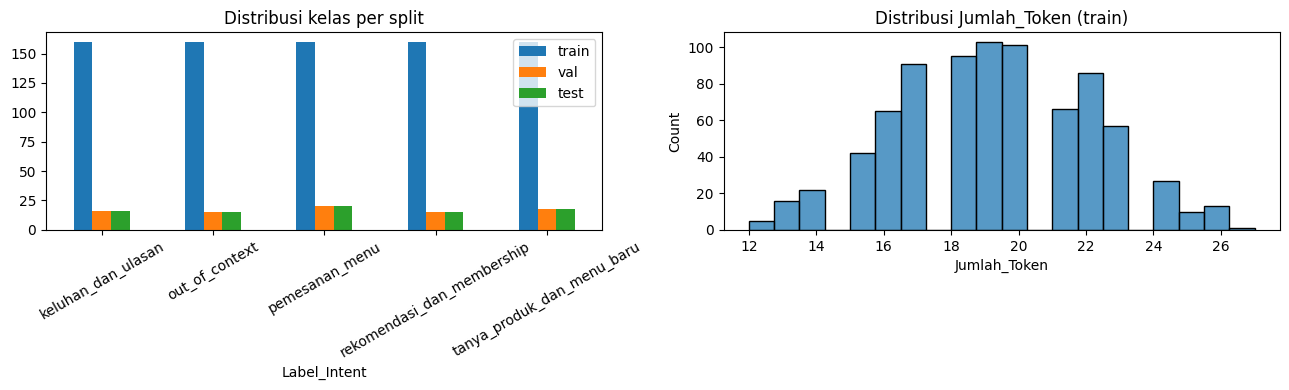

Teks bersih identik antara train & test: 0 dari 84 unik di test


In [9]:
dist = pd.DataFrame({"train": train[LABEL_COL].value_counts(),
                     "val": val[LABEL_COL].value_counts(),
                     "test": test[LABEL_COL].value_counts()}).loc[LABELS]
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dist.plot.bar(ax=ax[0]); ax[0].set_title("Distribusi kelas per split"); ax[0].tick_params(axis="x", rotation=30)
sns.histplot(train["Jumlah_Token"], bins=20, ax=ax[1]); ax[1].set_title("Distribusi Jumlah_Token (train)")
plt.tight_layout(); plt.show()

# Cek kebocoran: teks yang sama persis muncul di train DAN test
leak = set(train[CLEAN_COL]) & set(test[CLEAN_COL])
print(f"Teks bersih identik antara train & test: {len(leak)} dari {test[CLEAN_COL].nunique()} unik di test")

> **Catatan keterbatasan data.** Tidak ada teks identik antara train dan test, tetapi dataset ini bersifat *templat*: inti kalimat yang sama diulang dengan variasi sapaan/penutup ("Halo kak", "Thank you!", dll.). Karena itu model klasik sederhana pun bisa mencapai skor mendekati/sama dengan 100%, dan perbedaan sebelum vs sesudah tuning bisa nol. Ini bukan berarti model pasti sebaik itu pada pesan pelanggan nyata. Untuk laporan, catat sebagai keterbatasan dan lihat sel **Uji pesan baru** di bagian akhir.

## 3. Kandidat 2 — TF-IDF (N-gram 1,2) + Linear SVM / Logistic Regression
Dikerjakan lebih dulu karena cepat, sekaligus menjadi dasar komparasi *sebelum vs sesudah* tuning dan preprocessing.

### 3.1 Helper evaluasi (dipakai semua model → metrik seragam)

In [10]:
def evaluate(y_true, y_pred, name="", latency_ms=None):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro Precision": p, "Macro Recall": r, "Macro F1": f1,
            "Latency (ms/pesan)": latency_ms}

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(title)
    plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

def measure_latency_ms(predict_one, texts, warmup=5):
    """Rata-rata waktu inferensi 1 pesan (batch=1), dalam milidetik."""
    for t in texts[:warmup]: predict_one(t)
    t0 = time.perf_counter()
    for t in texts: predict_one(t)
    return (time.perf_counter() - t0) / len(texts) * 1000

### 3.2 Baseline: *sebelum* preprocessing & *sebelum* tuning
Dua skenario input dengan parameter default, untuk mengukur dampak **preprocessing** (`Pesan_Chat` mentah vs `Teks_Bersih`).

In [11]:
y_tr, y_va, y_te = train[LABEL_COL], val[LABEL_COL], test[LABEL_COL]

def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                     ("clf", clf)])

baseline_rows = []
for col, tag in [(RAW_COL, "mentah (Pesan_Chat)"), (CLEAN_COL, "bersih (Teks_Bersih)")]:
    for name, clf in [("Linear SVM", LinearSVC(random_state=SEED)),
                      ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=SEED))]:
        pipe = make_pipe(clf).fit(train[col], y_tr)
        row = evaluate(y_va, pipe.predict(val[col]), f"{name} | default | {tag}")
        baseline_rows.append(row)
baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df.drop(columns="Latency (ms/pesan)").round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Linear SVM | default | mentah (Pesan_Chat),1.0,1.0,1.0,1.0
1,Logistic Regression | default | mentah (Pesan_...,1.0,1.0,1.0,1.0
2,Linear SVM | default | bersih (Teks_Bersih),1.0,1.0,1.0,1.0
3,Logistic Regression | default | bersih (Teks_B...,1.0,1.0,1.0,1.0


### 3.3 Tuning dengan `GridSearchCV`
Hyperparameter yang disetel: `C`, `ngram_range`, `class_weight` (+ `min_df`/`sublinear_tf` ringan). Skor optimasi **macro-F1**, 5-fold stratified CV pada data **train saja** (val & test tidak ikut tuning).

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

param_grid_common = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2],
    "clf__C": [0.1, 0.5, 1, 5, 10],
    "clf__class_weight": [None, "balanced"],
}

searches = {
    "Linear SVM": GridSearchCV(make_pipe(LinearSVC(random_state=SEED)),
                               param_grid_common, scoring="f1_macro", cv=cv, n_jobs=-1, verbose=0),
    "Logistic Regression": GridSearchCV(make_pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
                                        param_grid_common, scoring="f1_macro", cv=cv, n_jobs=-1, verbose=0),
}

tuned = {}
for name, gs in searches.items():
    t0 = time.time()
    gs.fit(train[CLEAN_COL], y_tr)
    tuned[name] = gs
    print(f"{name:20s} | best CV macro-F1 = {gs.best_score_:.4f} | {time.time()-t0:.0f}s")
    print("   best params:", gs.best_params_)

Linear SVM           | best CV macro-F1 = 1.0000 | 20s
   best params: {'clf__C': 0.1, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Logistic Regression  | best CV macro-F1 = 1.0000 | 11s
   best params: {'clf__C': 0.1, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}


In [13]:
# Sebelum vs sesudah tuning (data: Teks_Bersih, evaluasi pada VALIDATION set)
base_clean = {r["Model"].split(" | ")[0]: r for r in baseline_rows if "Teks_Bersih" in r["Model"]}
cmp_rows = []
for name, gs in tuned.items():
    b = base_clean[name]
    a = evaluate(y_va, gs.predict(val[CLEAN_COL]), name)
    cmp_rows.append({"Model": name,
                     "Acc sebelum": b["Accuracy"], "Acc sesudah": a["Accuracy"],
                     "Macro-F1 sebelum": b["Macro F1"], "Macro-F1 sesudah": a["Macro F1"],
                     "Δ Macro-F1": a["Macro F1"] - b["Macro F1"]})
tuning_effect_df = pd.DataFrame(cmp_rows)
display(tuning_effect_df.round(4))

# Pilih varian ML terbaik berdasarkan macro-F1 validation
best_ml_name = max(tuned, key=lambda n: evaluate(y_va, tuned[n].predict(val[CLEAN_COL]), n)["Macro F1"])
best_ml = tuned[best_ml_name].best_estimator_
print("Kandidat 2 terpilih:", best_ml_name)

,Model,Acc sebelum,Acc sesudah,Macro-F1 sebelum,Macro-F1 sesudah,Δ Macro-F1
0,Linear SVM,1.0,1.0,1.0,1.0,0.0
1,Logistic Regression,1.0,1.0,1.0,1.0,0.0


Kandidat 2 terpilih: Linear SVM


## 4. Kandidat 1 — Fine-tuning IndoBERT (`indobenchmark/indobert-base-p1`)
Memakai loop PyTorch biasa (tanpa `Trainer`) agar tidak bergantung pada versi `transformers`. Input = `Pesan_Chat` mentah (tokenizer subword IndoBERT sudah menangani variasi teks; emoji dan huruf besar tetap dipertahankan sebagai sinyal). Epoch terbaik dipilih dari **macro-F1 validation**.

> Membutuhkan koneksi internet untuk mengunduh model dari Hugging Face. GPU sangat disarankan.

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

MODEL_NAME = "indobenchmark/indobert-base-p1"
BERT_TEXT_COL = RAW_COL        # ganti ke CLEAN_COL untuk uji varian teks bersih
MAX_LEN, BATCH, EPOCHS, LR = 64, 16, 6, 3e-5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("Device:", device)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)

class IntentDS(Dataset):
    def __init__(self, df):
        self.t = df[BERT_TEXT_COL].tolist()
        self.y = df[LABEL_COL].map(label2id).tolist()
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.t[i], self.y[i]

def collate(batch):
    texts, ys = zip(*batch)
    enc = tok(list(texts), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    enc["labels"] = torch.tensor(ys)
    return enc

dl_tr = DataLoader(IntentDS(train), batch_size=BATCH, shuffle=True,  collate_fn=collate)
dl_va = DataLoader(IntentDS(val),   batch_size=32,    shuffle=False, collate_fn=collate)
dl_te = DataLoader(IntentDS(test),  batch_size=32,    shuffle=False, collate_fn=collate)

Device: cpu


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [15]:
@torch.no_grad()
def bert_predict(model, loader):
    model.eval(); preds = []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items() if k != "labels"}
        preds += model(**b).logits.argmax(-1).cpu().tolist()
    return [id2label[i] for i in preds]

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(device)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total = len(dl_tr) * EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)

best_f1, best_state, history = -1, None, []
for ep in range(1, EPOCHS + 1):
    model.train(); loss_sum = 0
    for b in dl_tr:
        b = {k: v.to(device) for k, v in b.items()}
        loss = model(**b).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad()
        loss_sum += loss.item()
    m = evaluate(y_va, bert_predict(model, dl_va), "IndoBERT")
    history.append({"epoch": ep, "train_loss": loss_sum / len(dl_tr),
                    "val_acc": m["Accuracy"], "val_macro_f1": m["Macro F1"]})
    print(f"epoch {ep}: loss={history[-1]['train_loss']:.4f}  val_acc={m['Accuracy']:.4f}  val_macroF1={m['Macro F1']:.4f}")
    if m["Macro F1"] > best_f1:
        best_f1 = m["Macro F1"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
hist_df = pd.DataFrame(history); display(hist_df.round(4))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: loss=0.8111  val_acc=1.0000  val_macroF1=1.0000
epoch 2: loss=0.0060  val_acc=1.0000  val_macroF1=1.0000
epoch 3: loss=0.0023  val_acc=1.0000  val_macroF1=1.0000
epoch 4: loss=0.0018  val_acc=1.0000  val_macroF1=1.0000
epoch 5: loss=0.0015  val_acc=1.0000  val_macroF1=1.0000
epoch 6: loss=0.0014  val_acc=1.0000  val_macroF1=1.0000


,epoch,train_loss,val_acc,val_macro_f1
0,1,0.8111,1.0,1.0
1,2,0.0060,1.0,1.0
2,3,0.0023,1.0,1.0
3,4,0.0018,1.0,1.0
4,5,0.0015,1.0,1.0
5,6,0.0014,1.0,1.0


In [16]:
# Dampak fine-tuning: IndoBERT tanpa fine-tune (kepala klasifikasi acak) vs sesudah fine-tune (validation)
untrained = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(device)
m0 = evaluate(y_va, bert_predict(untrained, dl_va), "IndoBERT (sebelum fine-tune)")
m1 = evaluate(y_va, bert_predict(model, dl_va), "IndoBERT (sesudah fine-tune)")
display(pd.DataFrame([m0, m1]).drop(columns="Latency (ms/pesan)").round(4))
del untrained

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,IndoBERT (sebelum fine-tune),0.2381,0.1253,0.24,0.1435
1,IndoBERT (sesudah fine-tune),1.0000,1.0000,1.00,1.0000


## 5. Evaluasi akhir pada **Test Set terpisah**
Test set baru dipakai di sini, sekali saja, setelah semua pemilihan model/hyperparameter selesai pada train + val. Latency diukur per pesan (batch = 1) pada perangkat yang sama dengan eksekusi notebook.

In [17]:
test_texts_raw   = test[RAW_COL].tolist()
test_texts_clean = test[CLEAN_COL].tolist()

# --- Kandidat 2: ML (varian terbaik) ---
ml_pred = best_ml.predict(test_texts_clean)
ml_lat  = measure_latency_ms(lambda t: best_ml.predict([t]), test_texts_clean)
res_ml  = evaluate(y_te, ml_pred, f"TF-IDF + {best_ml_name} (tuned)", ml_lat)

# --- Kandidat 1: IndoBERT ---
@torch.no_grad()
def bert_one(text):
    model.eval()
    enc = tok(text, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
    out = model(**enc).logits.argmax(-1).item()
    if device.type == "cuda": torch.cuda.synchronize()
    return id2label[out]

bert_pred = bert_predict(model, dl_te)
bert_lat  = measure_latency_ms(bert_one, test_texts_raw if BERT_TEXT_COL == RAW_COL else test_texts_clean)
res_bert  = evaluate(y_te, bert_pred, "IndoBERT (fine-tuned)", bert_lat)

# Baseline ML (default, Teks_Bersih) pada test untuk pembanding "sebelum tuning"
base_pipe = make_pipe(LinearSVC(random_state=SEED)).fit(train[CLEAN_COL], y_tr)
res_base  = evaluate(y_te, base_pipe.predict(test_texts_clean), "TF-IDF + Linear SVM (default, sebelum tuning)",
                     measure_latency_ms(lambda t: base_pipe.predict([t]), test_texts_clean))

final_df = pd.DataFrame([res_bert, res_ml, res_base]).set_index("Model")
display(final_df.round(4))

,Accuracy,Macro Precision,Macro Recall,Macro F1,Latency (ms/pesan)
Model,,,,,
IndoBERT (fine-tuned),1.0,1.0,1.0,1.0,102.3841
TF-IDF + Linear SVM (tuned),1.0,1.0,1.0,1.0,0.9876
"TF-IDF + Linear SVM (default, sebelum tuning)",1.0,1.0,1.0,1.0,0.5448


IndoBERT (fine-tuned)
                            precision    recall  f1-score   support

        keluhan_dan_ulasan     1.0000    1.0000    1.0000        16
            out_of_context     1.0000    1.0000    1.0000        15
            pemesanan_menu     1.0000    1.0000    1.0000        20
rekomendasi_dan_membership     1.0000    1.0000    1.0000        15
tanya_produk_dan_menu_baru     1.0000    1.0000    1.0000        18

                  accuracy                         1.0000        84
                 macro avg     1.0000    1.0000    1.0000        84
              weighted avg     1.0000    1.0000    1.0000        84



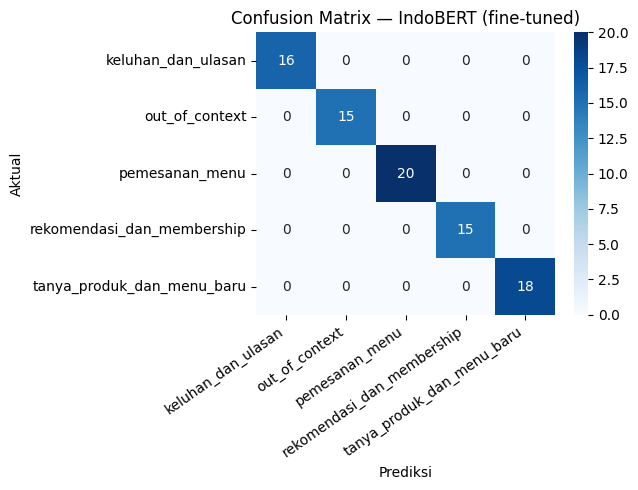

TF-IDF + Linear SVM (tuned)
                            precision    recall  f1-score   support

        keluhan_dan_ulasan     1.0000    1.0000    1.0000        16
            out_of_context     1.0000    1.0000    1.0000        15
            pemesanan_menu     1.0000    1.0000    1.0000        20
rekomendasi_dan_membership     1.0000    1.0000    1.0000        15
tanya_produk_dan_menu_baru     1.0000    1.0000    1.0000        18

                  accuracy                         1.0000        84
                 macro avg     1.0000    1.0000    1.0000        84
              weighted avg     1.0000    1.0000    1.0000        84



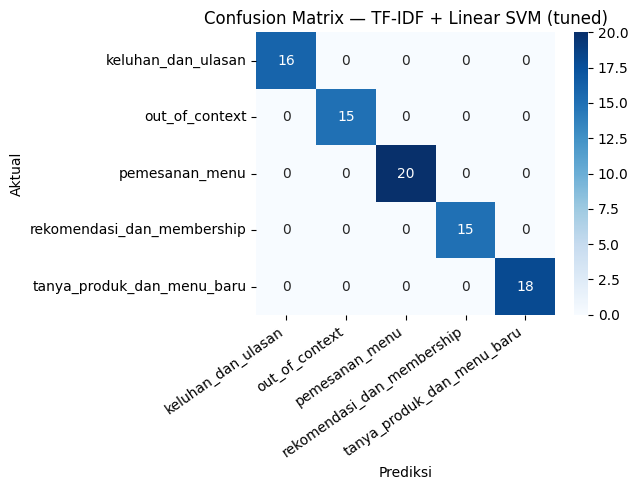

In [18]:
for name, pred in [("IndoBERT (fine-tuned)", bert_pred), (f"TF-IDF + {best_ml_name} (tuned)", ml_pred)]:
    print("="*70); print(name); print(classification_report(y_te, pred, digits=4, zero_division=0))
    plot_cm(y_te, pred, f"Confusion Matrix — {name}")

In [19]:
# Contoh kesalahan (jika ada)
for name, pred in [("IndoBERT", bert_pred), ("TF-IDF ML", ml_pred)]:
    wrong = test[np.array(pred) != y_te.values].copy()
    wrong["Prediksi"] = np.array(pred)[np.array(pred) != y_te.values]
    print(f"\n{name}: {len(wrong)} salah dari {len(test)}")
    if len(wrong): display(wrong[[RAW_COL, LABEL_COL, "Prediksi"]].head(10))


IndoBERT: 0 salah dari 84

TF-IDF ML: 0 salah dari 84


## 6. Pemilihan model terbaik
Aturan keputusan: (1) **Macro-F1 test** tertinggi; jika selisih < 1 poin persentase → (2) pilih yang **latency lebih rendah** dan **ukuran artefak lebih kecil**, karena model akan melayani chatbot real-time lewat FastAPI.

In [20]:
cand = {"IndoBERT": res_bert, "ML": res_ml}
f_bert, f_ml = res_bert["Macro F1"], res_ml["Macro F1"]
if abs(f_bert - f_ml) < 0.01:
    winner = "ML" if res_ml["Latency (ms/pesan)"] < res_bert["Latency (ms/pesan)"] else "IndoBERT"
    reason = "Selisih macro-F1 < 1 poin persentase, dipilih berdasarkan latency lebih rendah."
else:
    winner = "IndoBERT" if f_bert > f_ml else "ML"
    reason = "Macro-F1 test lebih tinggi."
print("Model terbaik:", winner, "→", reason)
print(f"Speed-up latency ML vs IndoBERT: {res_bert['Latency (ms/pesan)'] / max(res_ml['Latency (ms/pesan)'], 1e-9):.1f}x")

Model terbaik: ML → Selisih macro-F1 < 1 poin persentase, dipilih berdasarkan latency lebih rendah.
Speed-up latency ML vs IndoBERT: 103.7x


## 7. Simpan artefak untuk FastAPI

In [21]:
# Selalu simpan KEDUA artefak agar backend bisa memilih / fallback.
# --- ML: intent_svm.pkl + intent_tfidf.pkl (vectorizer & classifier dipisah sesuai spesifikasi) ---
joblib.dump(best_ml.named_steps["tfidf"], f"{ARTIFACT_DIR}/intent_tfidf.pkl")
joblib.dump(best_ml.named_steps["clf"],   f"{ARTIFACT_DIR}/intent_svm.pkl")   # bisa SVM atau LR sesuai pemenang tuning
joblib.dump(best_ml,                      f"{ARTIFACT_DIR}/intent_pipeline.pkl")

# --- IndoBERT: intent_classifier_model/ ---
bert_dir = f"{ARTIFACT_DIR}/intent_classifier_model"
model.save_pretrained(bert_dir); tok.save_pretrained(bert_dir)

meta = {"labels": LABELS, "label2id": label2id, "winner": winner,
        "ml_variant": best_ml_name, "bert_text_col": BERT_TEXT_COL,
        "ml_text_col": CLEAN_COL, "max_len": MAX_LEN}
json.dump(meta, open(f"{ARTIFACT_DIR}/intent_meta.json", "w"), indent=2)

final_df.round(4).to_csv(f"{ARTIFACT_DIR}/model_comparison.csv")
print(os.listdir(ARTIFACT_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['intent_meta.json', 'intent_classifier_model', 'intent_svm.pkl', 'intent_pipeline.pkl', 'intent_tfidf.pkl', 'model_comparison.csv']


In [22]:
# Tabel markdown siap tempel ke README.md
md_table = final_df.round(4).reset_index().to_markdown(index=False)
print(md_table)

| Model                                         |   Accuracy |   Macro Precision |   Macro Recall |   Macro F1 |   Latency (ms/pesan) |
|:----------------------------------------------|-----------:|------------------:|---------------:|-----------:|---------------------:|
| IndoBERT (fine-tuned)                         |          1 |                 1 |              1 |          1 |             102.384  |
| TF-IDF + Linear SVM (tuned)                   |          1 |                 1 |              1 |          1 |               0.9876 |
| TF-IDF + Linear SVM (default, sebelum tuning) |          1 |                 1 |              1 |          1 |               0.5448 |


**Template alasan pemilihan model untuk `README.md`** (isi angka setelah dijalankan):

> Dipilih **<model>** karena macro-F1 test = <x> (vs <y>), latency <a> ms vs <b> ms per pesan, dan ukuran artefak <c> MB vs <d> MB. Untuk chatbot kedai yang butuh respons cepat dan deploy ringan di FastAPI, ... Kelemahan: data bersifat templat sehingga skor tinggi perlu dibaca hati-hati; perlu data pesan nyata untuk uji generalisasi.

## 8. Uji pesan baru & contoh pemakaian di FastAPI

In [23]:
samples = [
    "kak ada promo apa hari ini buat member?",
    "aku mau pesen 2 es kopi susu gula aren dong atas nama Rani",
    "pelayanannya lambat banget tadi, kecewa",
    "kakak tau cara bikin website pake react nggak?",
    "menu baru bulan ini apa aja?",
    "kenapa langit berwarna biru?",
]
for s in samples:
    print(f"{s!r:75s} → ML: {best_ml.predict([s.lower()])[0]:28s} | BERT: {bert_one(s)}")

'kak ada promo apa hari ini buat member?'                                   → ML: rekomendasi_dan_membership   | BERT: rekomendasi_dan_membership
'aku mau pesen 2 es kopi susu gula aren dong atas nama Rani'                → ML: pemesanan_menu               | BERT: pemesanan_menu
'pelayanannya lambat banget tadi, kecewa'                                   → ML: keluhan_dan_ulasan           | BERT: keluhan_dan_ulasan
'kakak tau cara bikin website pake react nggak?'                            → ML: out_of_context               | BERT: rekomendasi_dan_membership
'menu baru bulan ini apa aja?'                                              → ML: tanya_produk_dan_menu_baru   | BERT: tanya_produk_dan_menu_baru
'kenapa langit berwarna biru?'                                              → ML: out_of_context               | BERT: tanya_produk_dan_menu_baru


In [24]:
# Contoh loader untuk FastAPI (salin ke app/intent.py)
snippet = '''
import joblib, json
tfidf = joblib.load("artifacts/intent_tfidf.pkl")
clf   = joblib.load("artifacts/intent_svm.pkl")

def predict_intent(text_clean: str) -> str:
    return clf.predict(tfidf.transform([text_clean]))[0]
'''
print(snippet)


import joblib, json
tfidf = joblib.load("artifacts/intent_tfidf.pkl")
clf   = joblib.load("artifacts/intent_svm.pkl")

def predict_intent(text_clean: str) -> str:
    return clf.predict(tfidf.transform([text_clean]))[0]

